<a href="https://colab.research.google.com/github/xumadison/DS4021---Lab-5-Neural-Networks-/blob/main/05_neural_networks_real_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Natalie Chandler, Ava Nguyen, Madison Xu"

## 0. Overall Instructions

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points) --> Ava & Natalie

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks.

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

- Descriptive Analysis: We will choose scatterplots and histograms to explore the relationships, and averages, median, to look at the shape of the data
- Data preprocessing: We will work on standardizing and scaling the data.
- Model configuration: We need a cost function, nn.MSELoss(), and no layer activation
- Performance evaluation: We will use 5 k-fold cross validation, and all pre-processing is done inside the loop.

## 2. Descriptive analysis (10 points) -> Ava

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('Concrete_Data.xls')
print(df.head())

   Cement (component 1)(kg in a m^3 mixture)  \
0                                      540.0   
1                                      540.0   
2                                      332.5   
3                                      332.5   
4                                      198.6   

   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
0                                                0.0       
1                                                0.0       
2                                              142.5       
3                                              142.5       
4                                              132.4       

   Fly Ash (component 3)(kg in a m^3 mixture)  \
0                                         0.0   
1                                         0.0   
2                                         0.0   
3                                         0.0   
4                                         0.0   

   Water  (component 4)(kg in a m^3 mixture)  \
0      

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)  

In [4]:
df.duplicated().sum()

np.int64(25)

In [5]:
print(df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(1030, 9)
(1005, 9)


In [6]:
df.isnull().sum()

,0
Cement (component 1)(kg in a m^3 mixture),0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),0
Fly Ash (component 3)(kg in a m^3 mixture),0
Water (component 4)(kg in a m^3 mixture),0
Superplasticizer (component 5)(kg in a m^3 mixture),0
Coarse Aggregate (component 6)(kg in a m^3 mixture),0
Fine Aggregate (component 7)(kg in a m^3 mixture),0
Age (day),0
"Concrete compressive strength(MPa, megapascals)",0


In [7]:
df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.629055,72.043134,55.535075,182.074378,6.031647,974.376468,772.686617,45.856716,35.250273
std,104.345003,86.170555,64.207448,21.340740,5.919559,77.579534,80.339851,63.734692,16.284808
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,190.680000,0.000000,0.000000,166.610000,0.000000,932.000000,724.300000,7.000000,23.523542
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.798114
75%,349.000000,142.500000,118.270000,192.940000,10.000000,1031.000000,822.200000,56.000000,44.868340
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [8]:
df.columns = ['Cement', 'Slag', 'FlyAsh', 'Water', 'Superplasticizer',
              'CoarseAgg', 'FineAgg', 'Age', 'Strength']

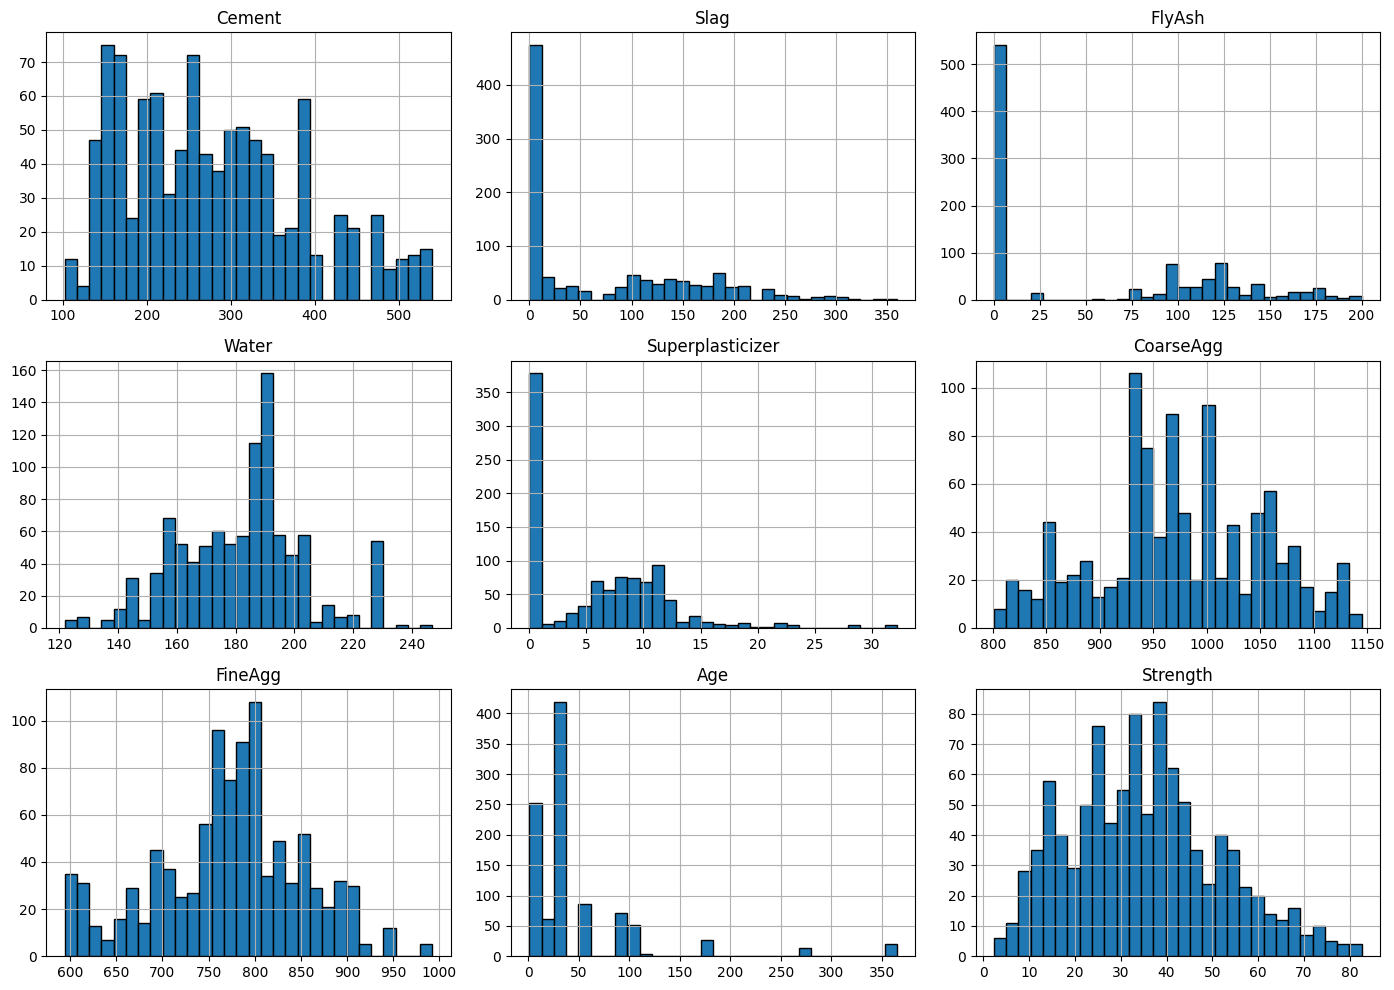

In [9]:
df.hist(bins=30, figsize=(14, 10), layout=(3, 3), edgecolor='black')
plt.tight_layout()
plt.show()

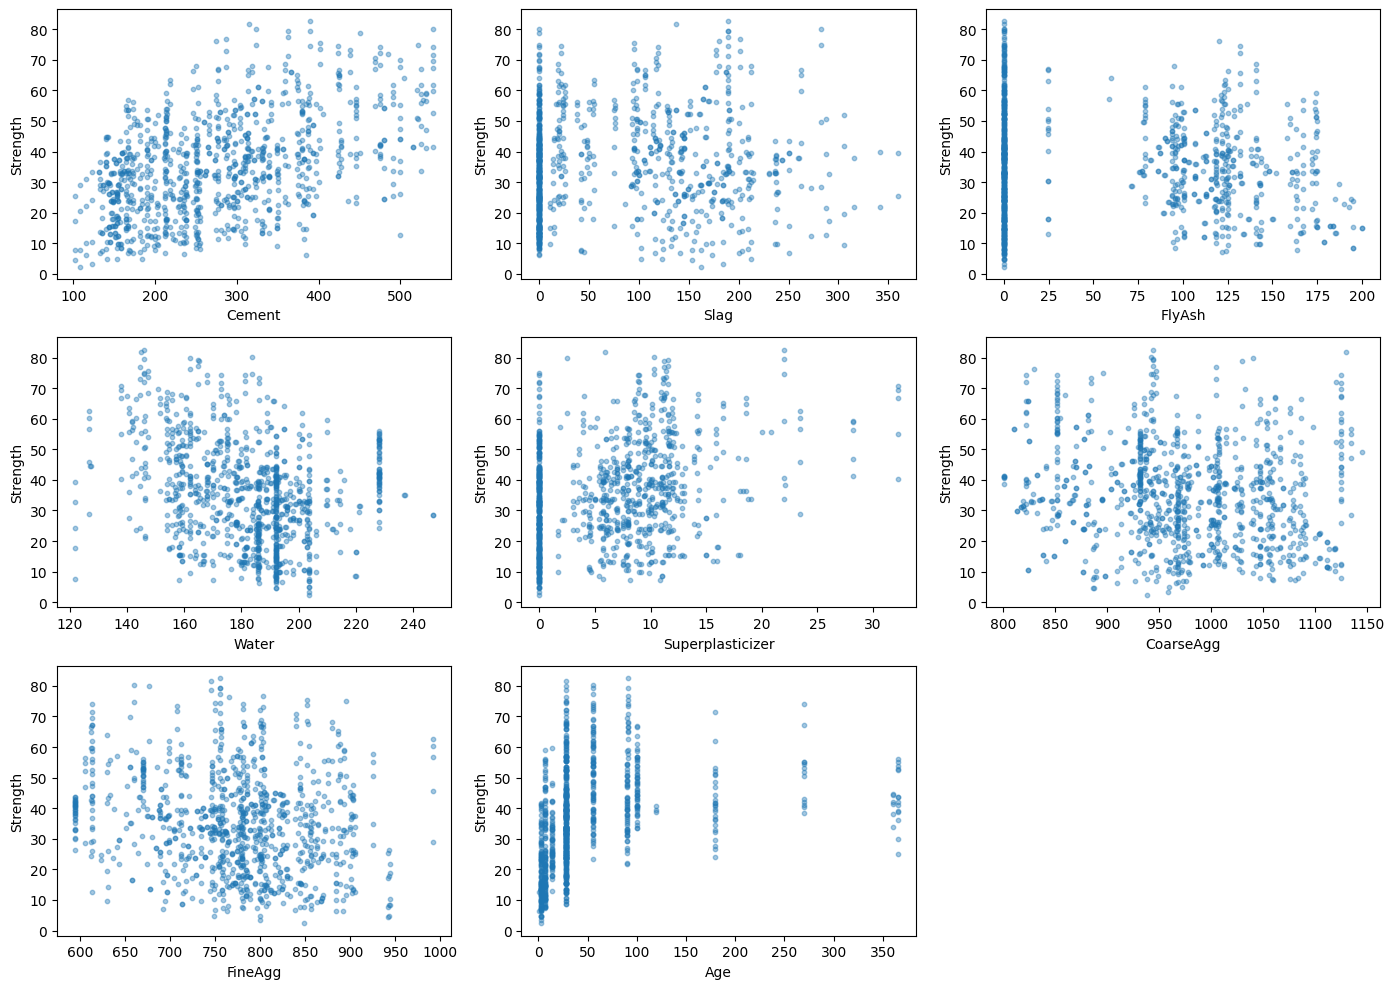

In [10]:
features = df.columns[:-1]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, features):
    ax.scatter(df[col], df['Strength'], alpha=0.4, s=10)
    ax.set_xlabel(col)
    ax.set_ylabel('Strength')
for ax in axes.flat[len(features):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
df.corr()['Strength'].sort_values(ascending=False)

,Strength
Strength,1.000000
Cement,0.488283
Superplasticizer,0.344225
Age,0.337371
Slag,0.103370
FlyAsh,-0.080648
CoarseAgg,-0.144710
FineAgg,-0.186457
Water,-0.269606


### Interpretation

Cement, Superplasticizer, and Age have the highest positive correlation with Strength. Water has the highest negative correlation.

Slag, FlyAsh, and Superplasticer have lots of zeroes, which means that many mixes didn't use them.

## 3. Neural Network (40 points) -> Maddie

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [12]:
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Inputs and outcome (cleaned df from Section 2)
X = df.drop(columns='Strength').values
y = df['Strength'].values

print(X.shape, y.shape)

(1005, 8) (1005,)


In [13]:
# Model
# Neural network for regression (8 -> 64 -> 32 -> 1)
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.linear_1 = nn.Linear(input_dim, 64)
        self.linear_2 = nn.Linear(64, 32)
        self.linear_3 = nn.Linear(32, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.linear_1(x))
        x = self.relu(self.linear_2(x))
        x = self.linear_3(x)  # No activation in the output layer: regression
        return x

In [14]:
# 5-fold CV, training and eval
torch.manual_seed(1234)

kf = KFold(n_splits=5, shuffle=True, random_state=1234)
batch_size = 32
n_epochs = 200

rmse_scores = []
mae_scores = []
r2_scores = []
all_train_costs = []
y_pred_all = np.zeros(len(y))  # Out-of-fold predictions, for plotting

for fold, (train_idx, test_idx) in enumerate(kf.split(X), 1):

    # 1- Split the data for this fold
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # 2- Scale inside the loop (fit on the training fold only)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # 3- Convert to tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

    # 4- Wrap the training data in a TensorDataset and DataLoader
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    # 5- Instantiate a new model, cost function and optimizer for each fold
    model = MLP(X_train.shape[1])
    cost_fn = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)

    # 6- Train
    train_costs = []
    for epoch in range(n_epochs):
        model.train()
        running_cost = 0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_pred = model(X_batch)
            cost = cost_fn(y_pred, y_batch)
            cost.backward()
            optimizer.step()
            running_cost += cost.item() * X_batch.shape[0]

        train_costs.append(running_cost / X_train.shape[0])

    all_train_costs.append(train_costs)

    # 7- Evaluate on the test fold
    model.eval()
    with torch.no_grad():
        y_test_pred = model(X_test)

    rmse = np.sqrt(mean_squared_error(y_test.numpy(), y_test_pred.numpy()))
    mae = mean_absolute_error(y_test.numpy(), y_test_pred.numpy())
    r2 = r2_score(y_test.numpy(), y_test_pred.numpy())

    rmse_scores.append(rmse)
    mae_scores.append(mae)
    r2_scores.append(r2)
    y_pred_all[test_idx] = y_test_pred.numpy().flatten()

    print(f"Fold {fold}: RMSE = {rmse:.2f} MPa, MAE = {mae:.2f} MPa, R² = {r2:.3f}")

Fold 1: RMSE = 5.46 MPa, MAE = 4.06 MPa, R² = 0.897
Fold 2: RMSE = 4.39 MPa, MAE = 3.52 MPa, R² = 0.919
Fold 3: RMSE = 5.07 MPa, MAE = 3.75 MPa, R² = 0.900
Fold 4: RMSE = 5.48 MPa, MAE = 4.08 MPa, R² = 0.884
Fold 5: RMSE = 6.15 MPa, MAE = 4.13 MPa, R² = 0.864


In [15]:
# avg results
# Average performance across the 5 folds
print("Neural Network (PyTorch), 5-fold CV")
print(f"  RMSE: {np.mean(rmse_scores):.2f} ± {np.std(rmse_scores):.2f} MPa")
print(f"  MAE:  {np.mean(mae_scores):.2f} ± {np.std(mae_scores):.2f} MPa")
print(f"  R²:   {np.mean(r2_scores):.3f} ± {np.std(r2_scores):.3f}")

Neural Network (PyTorch), 5-fold CV
  RMSE: 5.31 ± 0.58 MPa
  MAE:  3.91 ± 0.24 MPa
  R²:   0.893 ± 0.018


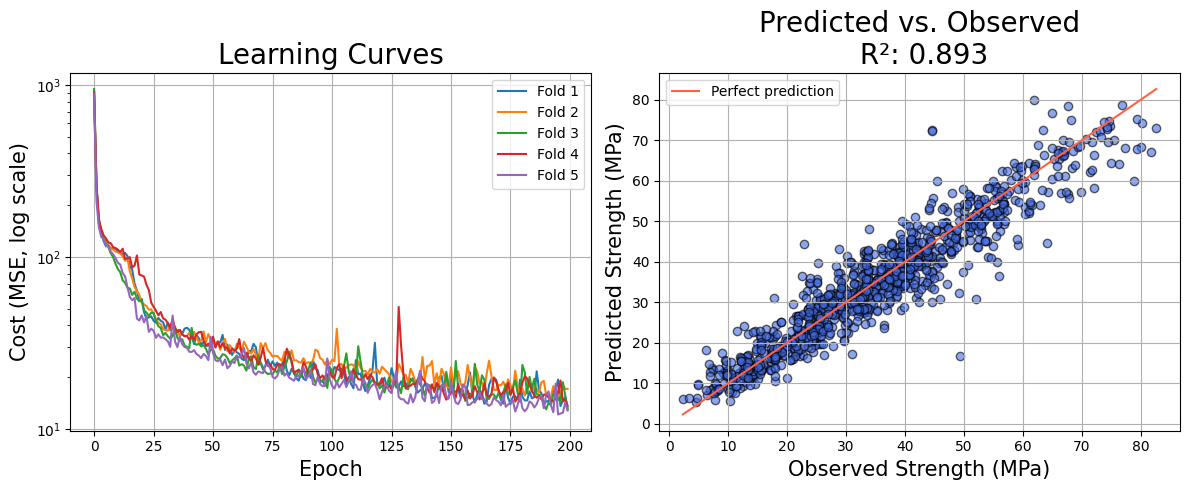

In [16]:
# plots
plt.figure(figsize=(12, 5))

# Learning curves (training cost per fold)
plt.subplot(1, 2, 1)
for i, train_costs in enumerate(all_train_costs, 1):
    plt.plot(train_costs, label=f"Fold {i}")
plt.yscale('log')
plt.title("Learning Curves", size=20)
plt.xlabel("Epoch", size=15)
plt.ylabel("Cost (MSE, log scale)", size=15)
plt.legend(loc='best')
plt.grid(True)

# Predicted vs. observed strength (out-of-fold predictions)
plt.subplot(1, 2, 2)
plt.scatter(y, y_pred_all, c='royalblue', edgecolor='k', alpha=0.6)
plt.plot([y.min(), y.max()], [y.min(), y.max()], c='tomato', label='Perfect prediction')
plt.title(f"Predicted vs. Observed\n R²: {np.mean(r2_scores):.3f}", size=20)
plt.xlabel("Observed Strength (MPa)", size=15)
plt.ylabel("Predicted Strength (MPa)", size=15)
plt.legend(loc='best')
plt.grid(True)

plt.tight_layout()
plt.show()

## 4. Replication (10 points) --> Ava

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [17]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points) -> Natalie

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_validate

scaler = StandardScaler()

In [19]:
df = pd.read_excel('Concrete_Data.xls')
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [20]:
# Data
y = df["Concrete compressive strength(MPa, megapascals) "]
X = df.drop(columns="Concrete compressive strength(MPa, megapascals) ")

In [21]:
# SVM (SVR) and Linear Regression
kf = KFold(n_splits=5, shuffle=True, random_state=1234)
metrics = ["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]

models = {
    "SVR (linear kernel)": make_pipeline(StandardScaler(), SVR(kernel="linear")),
    "Linear Regression":   make_pipeline(StandardScaler(), LinearRegression()),
}

for name, pipe in models.items():
    scores = cross_validate(pipe, X, y, cv=kf, scoring=metrics)
    rmse = -scores["test_neg_root_mean_squared_error"]
    mae  = -scores["test_neg_mean_absolute_error"]
    r2   =  scores["test_r2"]

    print(name)
    print(f"  RMSE: {rmse.mean():.2f} ± {rmse.std():.2f} MPa")
    print(f"  MAE:  {mae.mean():.2f} ± {mae.std():.2f} MPa")
    print(f"  R²:   {r2.mean():.3f} ± {r2.std():.3f}")


SVR (linear kernel)
  RMSE: 10.97 ± 0.62 MPa
  MAE:  8.31 ± 0.23 MPa
  R²:   0.565 ± 0.039
Linear Regression
  RMSE: 10.49 ± 0.19 MPa
  MAE:  8.30 ± 0.13 MPa
  R²:   0.602 ± 0.024


## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE